# Data Exploration

### Basic Information

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load data
df = pd.read_csv('../data/processed/station_model.csv')

print("Shape:", df.shape)
print("\nBasic stats on weekly_exits:")
print(df['weekly_exits'].describe())
print("\nBy year:")
print(df.groupby('Year')['weekly_exits'].mean().round(0))

Shape: (18188, 24)

Basic stats on weekly_exits:
count     18188.000000
mean      27804.599406
std       35676.785174
min           1.000000
25%        8545.000000
50%       17124.000000
75%       32805.500000
max      252314.000000
Name: weekly_exits, dtype: float64

By year:
Year
2017    42471.0
2018    40289.0
2019    39368.0
2023    15269.0
2024    16344.0
2025    17209.0
2026     9914.0
Name: weekly_exits, dtype: float64


### Fix Duplicate Issue

In [8]:
# Fix by grouping without Month, then recalculate Month as most common value
df_model_fixed = df.groupby(['Year', 'Week', 'Origin Station',
                              'origin_name', 'origin_lat', 'origin_lon',
                              'station_code', 'stop_name',
                              'stop_lat', 'stop_lon', 'ALAND',
                              'population_density', 'low_car_rate',
                              'transit_commuter_rate', 'driver_rate',
                              'carpool_rate', 'employment_rate',
                              'renter_rate', 'median_income']).agg(
    weekly_exits=('weekly_exits', 'sum'),
    avg_trip_distance_km=('avg_trip_distance_km', 'mean'),
    is_weekend_ratio=('is_weekend_ratio', 'mean'),
    num_unique_destinations=('num_unique_destinations', 'max'),
    Month=('Month', lambda x: x.mode()[0])  # most common month
).reset_index()

print("Shape:", df_model_fixed.shape)

# Check Embarcadero week 1 2019
embr_check = df_model_fixed[(df_model_fixed['Origin Station'] == 'EMBR') & 
                              (df_model_fixed['Year'] == 2019)]
print("\nEmbarcadero 2019 first 10 weeks:")
print(embr_check[['Week', 'Month', 'weekly_exits']].head(10))
print("\nDuplicate weeks:", embr_check['Week'].duplicated().sum())

Shape: (15149, 24)

Embarcadero 2019 first 10 weeks:
      Week  Month  weekly_exits
4761     1      1        168371
4808     2      1        222431
4855     3      1        223352
4902     4      1        202404
4949     5      1        222374
4996     6      2        218862
5043     7      2        215342
5090     8      2        192871
5137     9      2        217083
5184    10      3        218048

Duplicate weeks: 0


In [14]:
df_model_fixed = df_model_fixed[~((df_model_fixed['Year'] == 2026) & 
                                   (df_model_fixed['Week'].isin([1, 6])))]

print("Shape after removing incomplete weeks:", df_model_fixed.shape)
print("\n2026 system-wide weekly totals after fix:")
print(df_model_fixed[df_model_fixed['Year'] == 2026].groupby('Week')['weekly_exits'].sum())
print("\nAverage weekly exits by year:")
print(df_model_fixed.groupby('Year')['weekly_exits'].mean().round(0))

Shape after removing incomplete weeks: (15051, 24)

2026 system-wide weekly totals after fix:
Week
2    747458
3    805767
4    738361
5    785340
Name: weekly_exits, dtype: int64

Average weekly exits by year:
Year
2017    51435.0
2018    48754.0
2019    46900.0
2023    18499.0
2024    19487.0
2025    20519.0
2026    15699.0
Name: weekly_exits, dtype: float64


In [15]:
df_model_fixed.to_csv('../data/processed/df_model.csv', index=False)
print("Saved successfully")
print(f"Shape: {df_model_fixed.shape}")
print(f"\nYears present: {sorted(df_model_fixed['Year'].unique())}")
print(f"Stations present: {df_model_fixed['Origin Station'].nunique()}")
print(f"\nAverage weekly exits by year:")
print(df_model_fixed.groupby('Year')['weekly_exits'].mean().round(0))

Saved successfully
Shape: (15051, 24)

Years present: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Stations present: 49

Average weekly exits by year:
Year
2017    51435.0
2018    48754.0
2019    46900.0
2023    18499.0
2024    19487.0
2025    20519.0
2026    15699.0
Name: weekly_exits, dtype: float64


 ### Fixed Look at basic stats

In [16]:
df = pd.read_csv('../data/processed/df_model.csv')

print("Shape:", df.shape)
print("\nBasic stats on weekly_exits:")
print(df['weekly_exits'].describe())
print("\nBy year:")
print(df.groupby('Year')['weekly_exits'].mean().round(0))

Shape: (15051, 24)

Basic stats on weekly_exits:
count     15051.000000
mean      33578.276992
std       38881.491388
min           1.000000
25%       12128.500000
50%       21441.000000
75%       38222.000000
max      252314.000000
Name: weekly_exits, dtype: float64

By year:
Year
2017    51435.0
2018    48754.0
2019    46900.0
2023    18499.0
2024    19487.0
2025    20519.0
2026    15699.0
Name: weekly_exits, dtype: float64


## Graphs

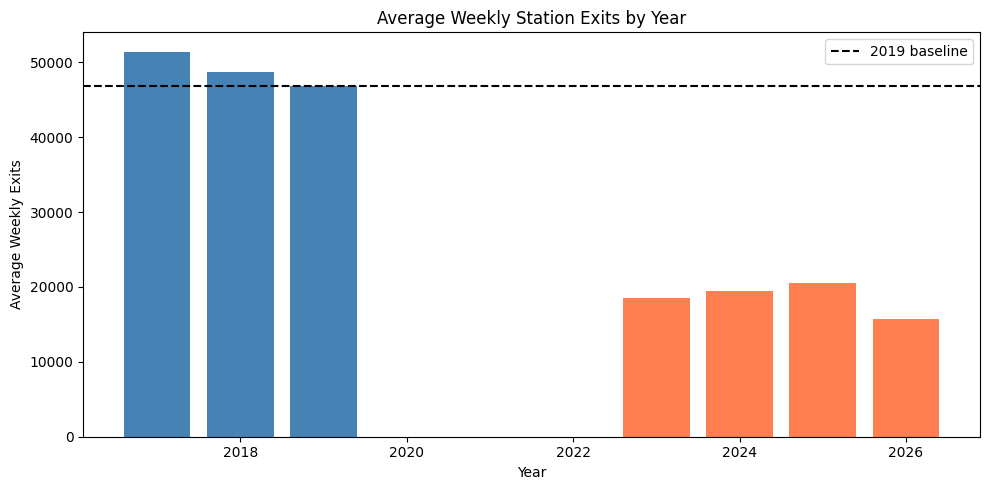

2026 note: partial year (6 weeks only)


In [17]:
import os
os.makedirs('../notebooks/figures', exist_ok=True)

# Plot 1: Average weekly exits by year
yearly_avg = df.groupby('Year')['weekly_exits'].mean()

plt.figure(figsize=(10, 5))
colors = ['steelblue' if y < 2020 else 'coral' for y in yearly_avg.index]
plt.bar(yearly_avg.index, yearly_avg.values, color=colors)
plt.axhline(y=yearly_avg[2019], color='black', linestyle='--', label='2019 baseline')
plt.title('Average Weekly Station Exits by Year')
plt.xlabel('Year')
plt.ylabel('Average Weekly Exits')
plt.legend()
plt.tight_layout()
plt.savefig('../notebooks/figures/yearly_ridership.png', dpi=150)
plt.show()
print("2026 note: partial year (6 weeks only)")

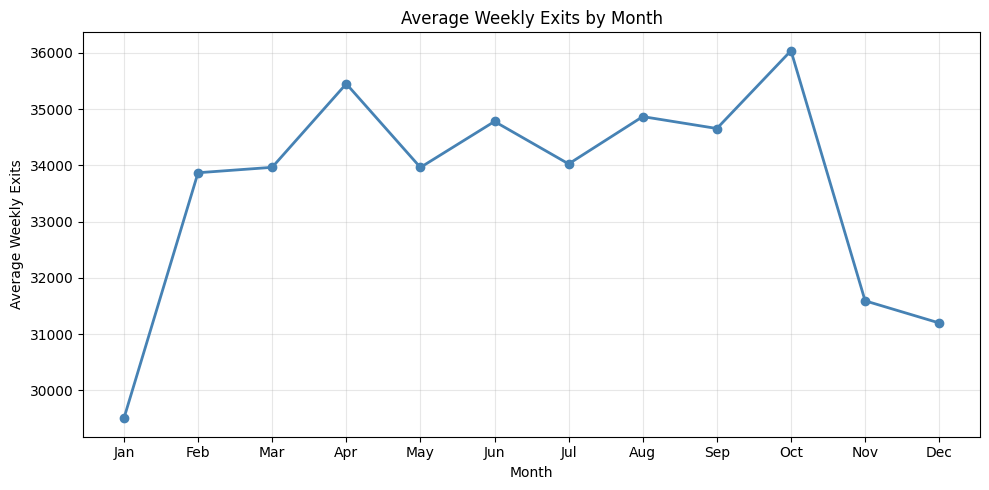

In [20]:
# Average weekly exits by month
monthly_avg = df.groupby('Month')['weekly_exits'].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly_avg.index, monthly_avg.values, marker='o', color='steelblue', linewidth=2)
plt.title('Average Weekly Exits by Month')
plt.xlabel('Month')
plt.ylabel('Average Weekly Exits')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                            'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../notebooks/figures/monthly_ridership.png', dpi=150)
plt.show()

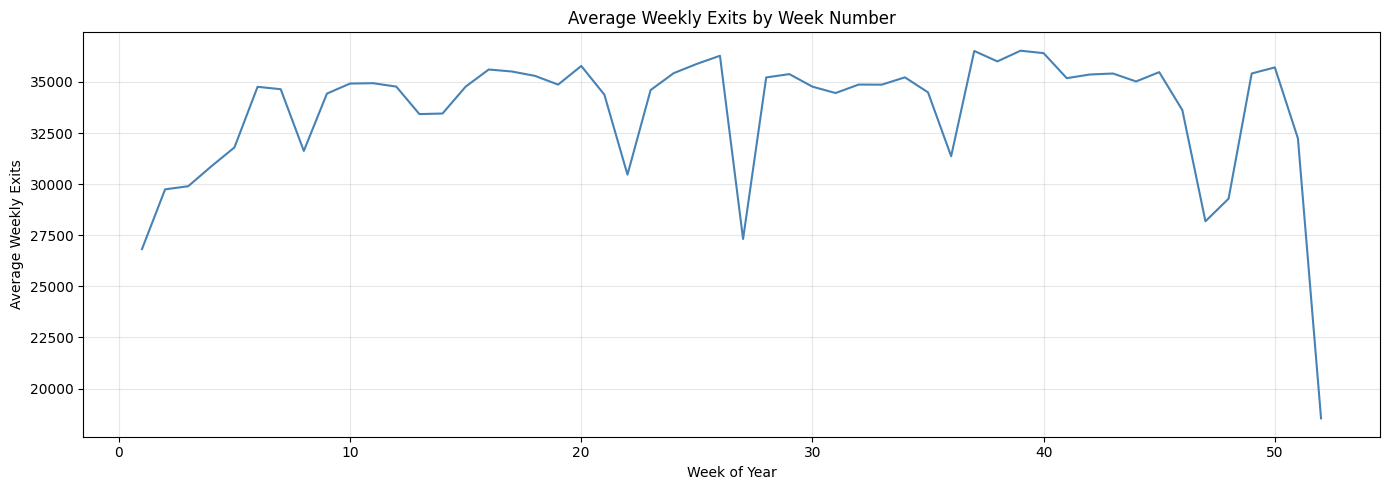

In [21]:
# Average weekly exits by week number
weekly_avg = df.groupby('Week')['weekly_exits'].mean()

plt.figure(figsize=(14, 5))
plt.plot(weekly_avg.index, weekly_avg.values, color='steelblue', linewidth=1.5)
plt.title('Average Weekly Exits by Week Number')
plt.xlabel('Week of Year')
plt.ylabel('Average Weekly Exits')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../notebooks/figures/weekly_ridership.png', dpi=150)
plt.show()

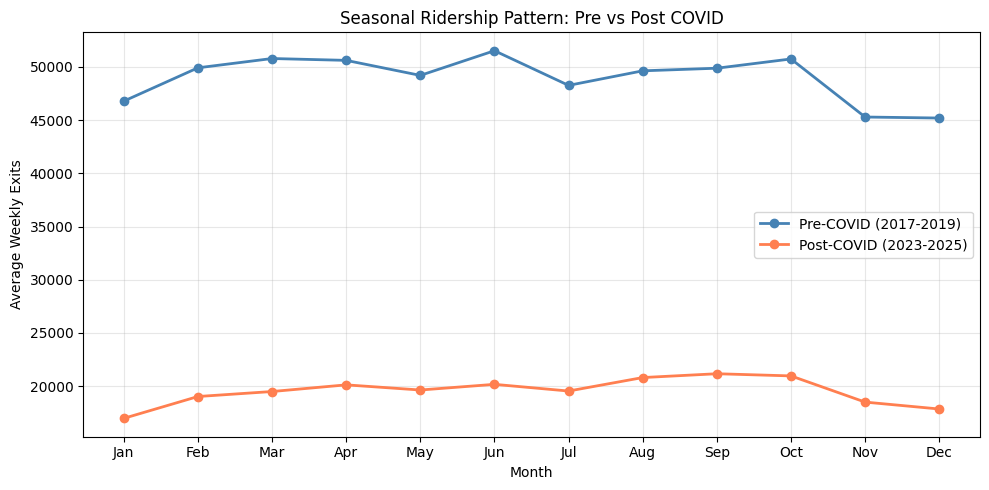

In [22]:
# Pre vs post COVID by month
pre_covid = df[df['Year'].isin([2017, 2018, 2019])].groupby('Month')['weekly_exits'].mean()
post_covid = df[df['Year'].isin([2023, 2024, 2025])].groupby('Month')['weekly_exits'].mean()

plt.figure(figsize=(10, 5))
plt.plot(pre_covid.index, pre_covid.values, marker='o', 
         color='steelblue', linewidth=2, label='Pre-COVID (2017-2019)')
plt.plot(post_covid.index, post_covid.values, marker='o', 
         color='coral', linewidth=2, label='Post-COVID (2023-2025)')
plt.title('Seasonal Ridership Pattern: Pre vs Post COVID')
plt.xlabel('Month')
plt.ylabel('Average Weekly Exits')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                            'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../notebooks/figures/seasonal_pre_post_covid.png', dpi=150)
plt.show()

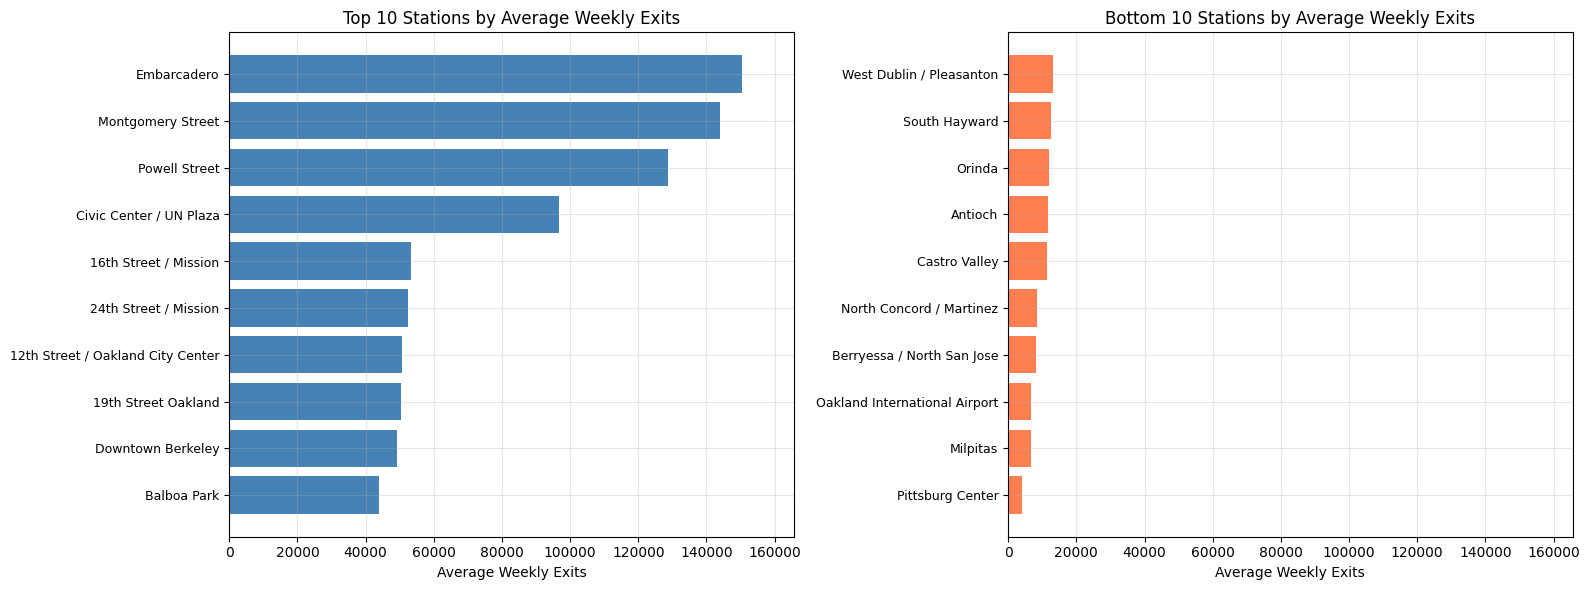

In [25]:
# Top 10 and Bottom 10 stations by overall average weekly exits
station_avg = df.groupby('origin_name')['weekly_exits'].mean().sort_values(ascending=False)

top10 = station_avg.head(10)
bottom10 = station_avg.tail(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

max_val = top10.values.max() * 1.1

# Top 10
ax1.barh(range(10), top10.values[::-1], color='steelblue')
ax1.set_yticks(range(10))
ax1.set_yticklabels(top10.index[::-1], fontsize=9)
ax1.set_xlabel('Average Weekly Exits')
ax1.set_title('Top 10 Stations by Average Weekly Exits')
ax1.set_xlim(0, max_val)
ax1.grid(True, alpha=0.3)

# Bottom 10
ax2.barh(range(10), bottom10.values[::-1], color='coral')
ax2.set_yticks(range(10))
ax2.set_yticklabels(bottom10.index[::-1], fontsize=9)
ax2.set_xlabel('Average Weekly Exits')
ax2.set_title('Bottom 10 Stations by Average Weekly Exits')
ax2.set_xlim(0, max_val)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../notebooks/figures/top_bottom_stations.png', dpi=150)
plt.show()

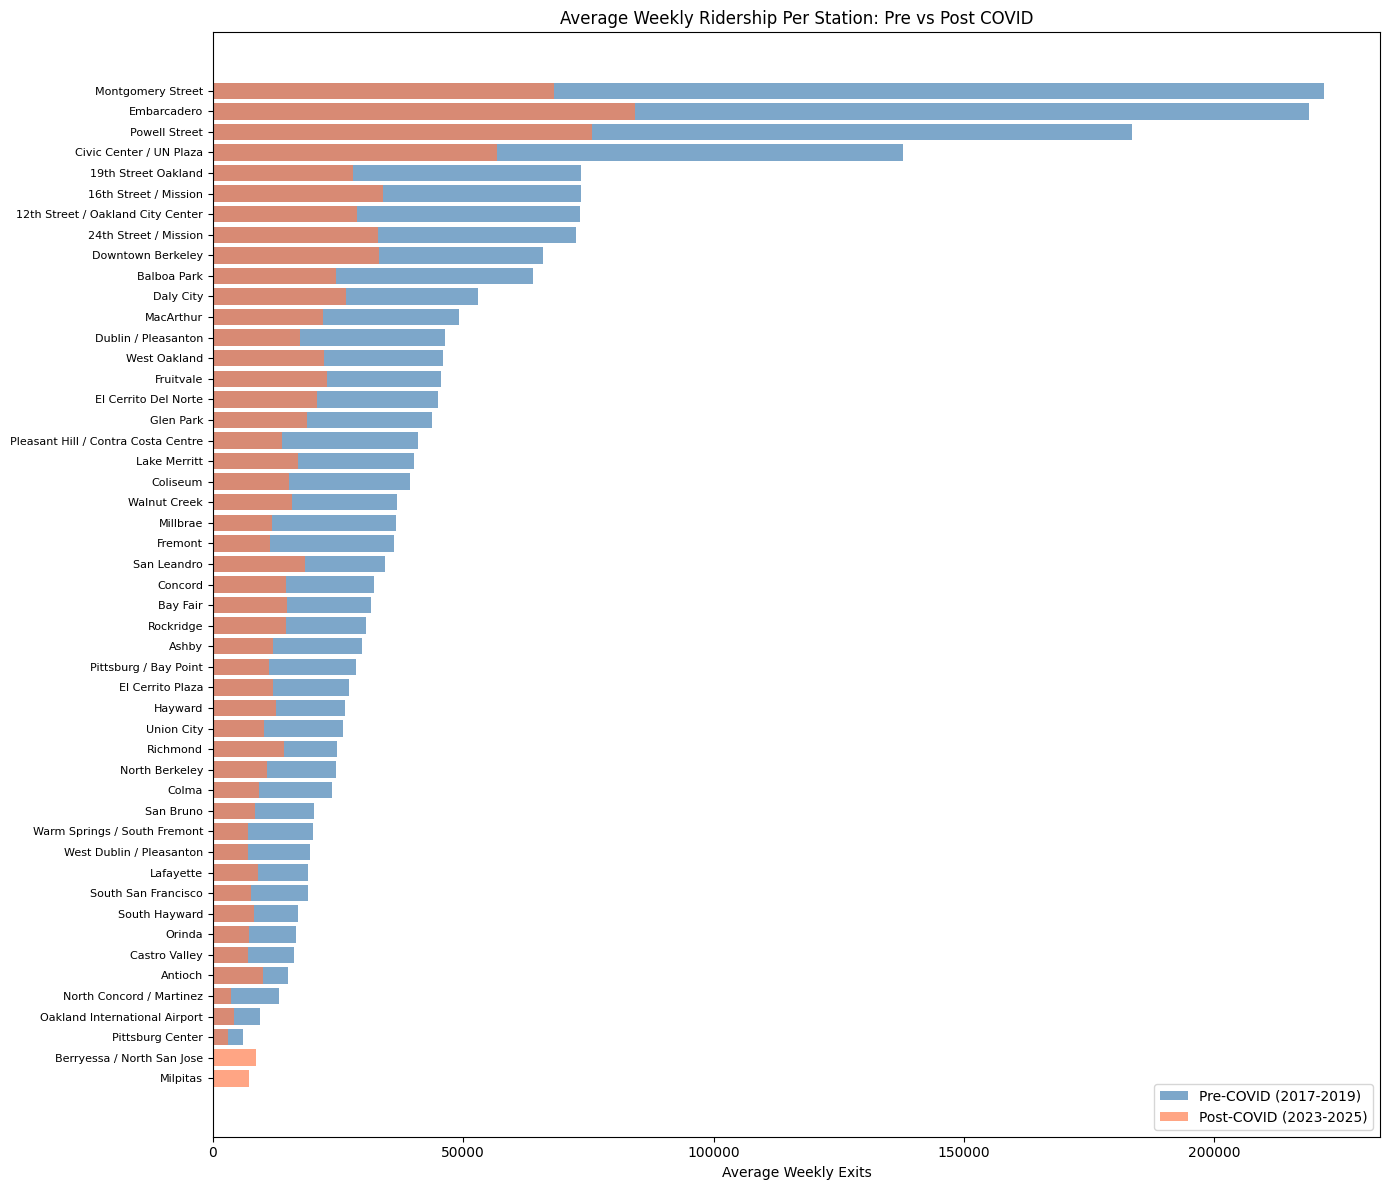

In [26]:
# Pre vs Post COVID average ridership per station
pre_covid = df[df['Year'].isin([2017, 2018, 2019])].groupby('origin_name')['weekly_exits'].mean()
post_covid = df[df['Year'].isin([2023, 2024, 2025])].groupby('origin_name')['weekly_exits'].mean()

comparison = pd.DataFrame({'Pre-COVID': pre_covid, 'Post-COVID': post_covid}).sort_values('Pre-COVID', ascending=True)

plt.figure(figsize=(14, 12))
x = range(len(comparison))
plt.barh(list(x), comparison['Pre-COVID'].values, alpha=0.7, color='steelblue', label='Pre-COVID (2017-2019)')
plt.barh(list(x), comparison['Post-COVID'].values, alpha=0.7, color='coral', label='Post-COVID (2023-2025)')
plt.yticks(list(x), comparison.index, fontsize=8)
plt.xlabel('Average Weekly Exits')
plt.title('Average Weekly Ridership Per Station: Pre vs Post COVID')
plt.legend()
plt.tight_layout()
plt.savefig('../notebooks/figures/pre_post_covid_per_station.png', dpi=150)
plt.show()

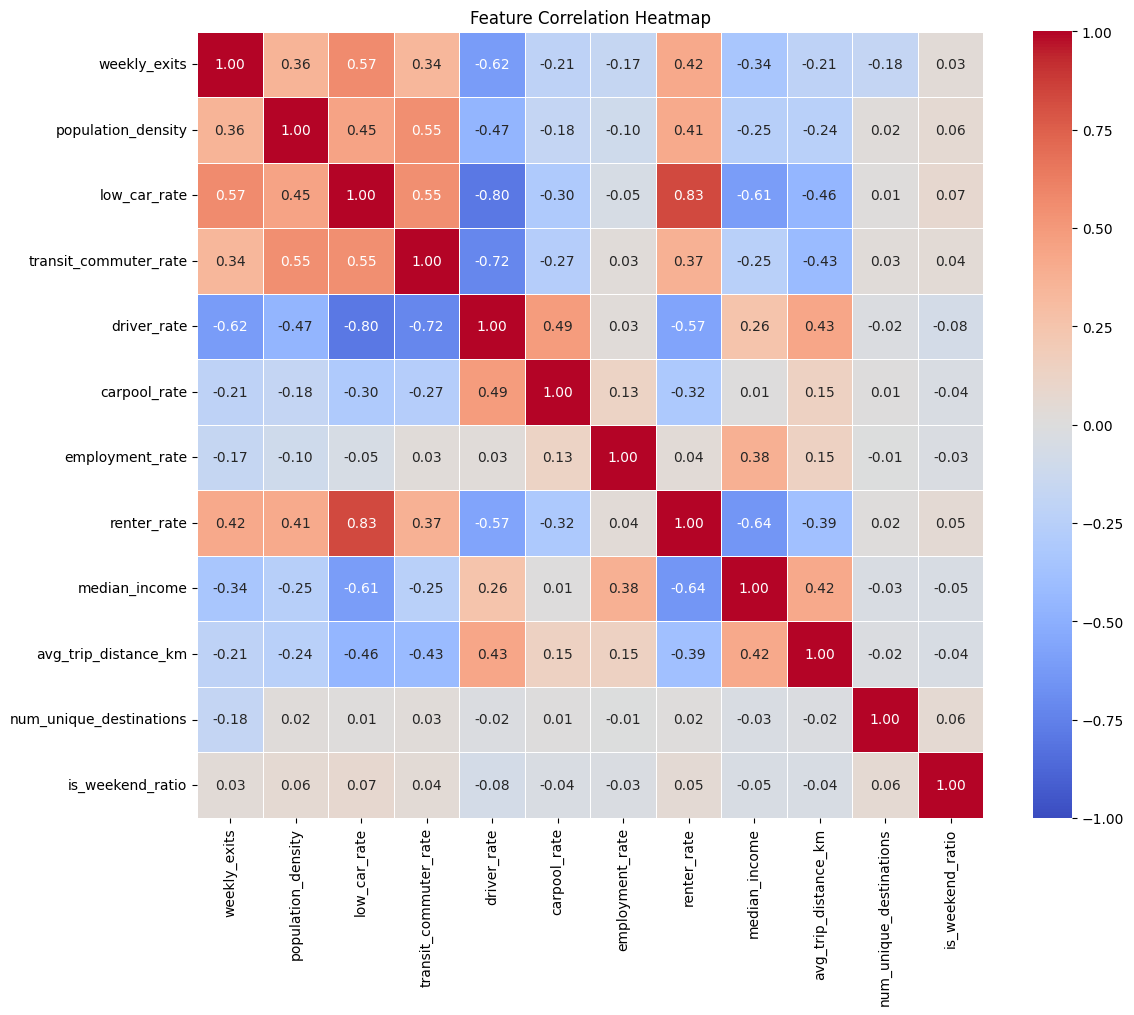

In [27]:
# Correlation heatmap of features vs weekly_exits
features = [
    'weekly_exits',
    'population_density',
    'low_car_rate',
    'transit_commuter_rate',
    'driver_rate',
    'carpool_rate',
    'employment_rate',
    'renter_rate',
    'median_income',
    'avg_trip_distance_km',
    'num_unique_destinations',
    'is_weekend_ratio'
]

corr_matrix = df[features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, 
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm',
            center=0,
            vmin=-1, 
            vmax=1,
            square=True,
            linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig('../notebooks/figures/correlation_heatmap.png', dpi=150)
plt.show()